In [20]:
#DATA SIMULATION & NOISE INJECTION (TẠO DỮ LIỆU GIẢ LẬP & CỐ TÌNH CHÈN LỖI)

import pandas as pd  #Import library for data manipulation (like Excel) / Nhập thư viện xử lý bảng dữ liệu (giống Excel)
import numpy as np   #Import library for numerical operations / Nhập thư viện tính toán số học

np.random.seed(42)   #Set random seed for reproducibility / Cố định hạt giống ngẫu nhiên để đảm bảo tính tái lập
n_samples = 3000     #Define total number of records / Quy định tổng số dòng dữ liệu là 3.000 đơn hàng

#Create lists of sample categories / Tạo danh sách các giá trị mẫu để chọn ngẫu nhiên
vendors = [f'VND_{i:02d}' for i in range(1, 21)] #Generate 20 vendor IDs (VND_01 to VND_20) / Tạo 20 mã nhà cung cấp
categories = ['Solar_Panel', 'Inverter', 'Mounting_Structure', 'Cables'] # Material categories / 4 nhóm vật tư
payment_terms = ['Net30', 'Net60', 'Advance_50%'] #Payment terms / 3 điều khoản thanh toán

#Build dictionary of columns / Tạo các cột dữ liệu cho bảng
data = {
    'PO_ID': [f'PO-2025-{i:04d}' for i in range(1, n_samples + 1)], #Purchase Order ID / Mã đơn đặt hàng
    'Vendor_ID': np.random.choice(vendors, n_samples),              #Randomly assign vendors / Chọn ngẫu nhiên nhà cung cấp
    'Category': np.random.choice(categories, n_samples, p=[0.4, 0.25, 0.2, 0.15]), #Assign category by probability / Chọn vật tư theo tỷ lệ %
    'Order_Quantity': np.random.randint(10, 500, n_samples),        #Random order quantity (10-500) / Số lượng đặt ngẫu nhiên
    'Payment_Terms': np.random.choice(payment_terms, n_samples),    #Randomly assign payment terms / Chọn ngẫu nhiên điều khoản thanh toán
    'Distance_km': np.random.randint(20, 1200, n_samples).astype(float), #Delivery distance in km / Khoảng cách vận chuyển (km)
    'Historical_OnTime_Rate': np.round(np.random.uniform(0.60, 0.99, n_samples), 2) #Past on-time rate (60%-99%) / Tỷ lệ giao đúng hẹn quá khứ
}

df = pd.DataFrame(data) #Convert dictionary into a DataFrame table / Chuyển đổi thành bảng tính hoàn chỉnh tên 'df'

#Generate market benchmark price and quoted unit price / Tạo giá tham chiếu thị trường và giá nhà cung cấp báo
base_prices = {'Solar_Panel': 120, 'Inverter': 1500, 'Mounting_Structure': 45, 'Cables': 15} # Standard unit prices / Giá chuẩn từng loại
df['Market_Benchmark_Price'] = df['Category'].map(base_prices) #Map standard price to each row / Điền giá chuẩn tương ứng từng vật tư
df['Quoted_Unit_Price'] = np.round(df['Market_Benchmark_Price'] * np.random.uniform(0.90, 1.25, n_samples), 2) #Quoted price varies -10% to +25% / Giá báo dao động -10% đến +25%

#Simulate realistic delay probability / Tạo công thức xác suất giao hàng trễ theo quy luật thực tế
delay_prob = (
    (1 - df['Historical_OnTime_Rate']) * 1.5 + #Lower vendor reliability increases delay risk / Nhà cung cấp hay trễ -> tăng rủi ro
    (df['Distance_km'] / 2000) +               #Longer distance increases delay risk / Khoảng cách xa -> tăng rủi ro
    (df['Order_Quantity'] / 1500) +            #Larger volume increases delay risk / Số lượng đặt lớn -> tăng rủi ro
    np.random.normal(0, 0.1, n_samples)        #Add random real-world noise / Cộng thêm yếu tố ngẫu nhiên thực tế
)
df['Is_Delayed'] = (delay_prob > 0.85).astype(int) #Label 1 if delayed (>0.85), else 0 / Đánh dấu 1 là Trễ, 0 là Đúng hạn

#INJECT DIRTY DATA FOR CLEANING PRACTICE / CỐ TÌNH TẠO DỮ LIỆU BẨN ĐỂ THỰC HÀNH LÀM SẠCH ---
df.loc[df.sample(frac=0.05, random_state=42).index, 'Historical_OnTime_Rate'] = np.nan # Inject 5% missing values / Xóa trống 5% dữ liệu tỷ lệ đúng hẹn
df.loc[df.sample(frac=0.04, random_state=24).index, 'Distance_km'] = np.nan # Inject 4% missing values / Xóa trống 4% dữ liệu khoảng cách

anomaly_idx = df.sample(frac=0.02, random_state=10).index #Select 2% rows for price anomalies / Chọn 2% số dòng để tạo lỗi đơn giá
df.loc[anomaly_idx[:30], 'Quoted_Unit_Price'] = df.loc[anomaly_idx[:30], 'Quoted_Unit_Price'] * 10 #10x typo error / Lỗi nhập dư số 0 (gấp 10 lần)
df.loc[anomaly_idx[30:], 'Quoted_Unit_Price'] = -50.0 #Negative price error / Lỗi nhập giá âm (-50)

duplicates = df.sample(n=50, random_state=99) #Sample 50 rows to duplicate / Lấy ngẫu nhiên 50 dòng
df = pd.concat([df, duplicates], ignore_index=True) #Append duplicates to table / Dán nối vào cuối bảng tạo lỗi trùng lặp

df.to_csv('raw_procurement_data.csv', index=False) #Export raw dirty dataset to CSV / Xuất ra file CSV dữ liệu thô
print(f"Raw dataset created: {len(df)} rows, {df.shape[1]} columns.") #Print summary / In thông báo số dòng và cột
df.head() #Preview first 5 rows / Xem trước 5 dòng đầu tiên

Raw dataset created: 3050 rows, 10 columns.


,PO_ID,Vendor_ID,Category,Order_Quantity,Payment_Terms,Distance_km,Historical_OnTime_Rate,Market_Benchmark_Price,Quoted_Unit_Price,Is_Delayed
0,PO-2025-0001,VND_07,Solar_Panel,391,Net30,479.0,NaN,120,119.26,0
1,PO-2025-0002,VND_20,Solar_Panel,427,Advance_50%,80.0,0.95,120,123.77,0
2,PO-2025-0003,VND_15,Inverter,53,Net30,388.0,0.95,1500,1813.17,0
3,PO-2025-0004,VND_11,Solar_Panel,280,Advance_50%,1164.0,0.61,120,147.92,1
4,PO-2025-0005,VND_08,Inverter,87,Advance_50%,738.0,0.75,1500,1726.15,0


In [21]:
#DATA VALIDATION & CLEANING (KIỂM THỬ & LÀM SẠCH DỮ LIỆU)
df_raw = pd.read_csv('raw_procurement_data.csv') #Load raw CSV dataset / Đọc file dữ liệu thô vào bảng 'df_raw'
print("--- INITIAL DATA QUALITY AUDIT / KIỂM TRA CHẤT LƯỢNG DỮ LIỆU BAN ĐẦU ---")
print(f"Total initial rows / Tổng số dòng ban đầu: {len(df_raw)}") #Count total rows / Đếm tổng số dòng
print(f"Duplicate PO_IDs / Số dòng trùng mã đơn hàng: {df_raw.duplicated(subset=['PO_ID']).sum()}") #Count duplicate IDs / Đếm số dòng trùng lặp
print(f"Invalid prices (<= 0) / Số dòng đơn giá âm hoặc bằng 0: {(df_raw['Quoted_Unit_Price'] <= 0).sum()}") #Count negative/zero prices / Đếm lỗi giá <= 0
print("\nMissing values per column / Số ô bị trống theo từng cột:")
print(df_raw.isnull().sum()[df_raw.isnull().sum() > 0]) #List columns with missing values / Liệt kê các cột có dữ liệu trống

df_clean = df_raw.copy() #Create a copy for cleaning / Tạo bản sao để làm sạch (giữ nguyên bản gốc)

#Step 1: Remove duplicate records / Bước 1: Xóa các dòng trùng lặp mã đơn hàng
df_clean = df_clean.drop_duplicates(subset=['PO_ID'], keep='first') #Keep first occurrence / Giữ dòng đầu tiên, xóa dòng trùng phía sau

#Step 2: Filter out pricing anomalies / Bước 2: Loại bỏ các đơn giá bất thường (<= 0 hoặc cao > 3 lần giá thị trường)
invalid_price_mask = (df_clean['Quoted_Unit_Price'] <= 0) | (df_clean['Quoted_Unit_Price'] > df_clean['Market_Benchmark_Price'] * 3) #Identify invalid rows / Đánh dấu dòng lỗi giá
print(f"\nRemoved {invalid_price_mask.sum()} rows with anomalous prices / Đã loại bỏ {invalid_price_mask.sum()} dòng lỗi đơn giá.")
df_clean = df_clean[~invalid_price_mask] #Keep only valid rows (~ means NOT) / Chỉ giữ lại các dòng hợp lệ

#Step 3: Impute missing values / Bước 3: Điền dữ liệu khuyết bằng giá trị trung vị (Median)
df_clean['Historical_OnTime_Rate'] = df_clean['Historical_OnTime_Rate'].fillna( #Fill missing vendor rate / Điền ô trống tỷ lệ đúng hẹn bằng:
    df_clean.groupby('Vendor_ID')['Historical_OnTime_Rate'].transform('median') #Median rate of that specific vendor / Trung vị của chính nhà cung cấp đó
)
df_clean['Distance_km'] = df_clean['Distance_km'].fillna(df_clean['Distance_km'].median()) #Fill missing distance with overall median / Điền khoảng cách trống bằng trung vị chung

print(f"\nCleaning completed! Clean rows remaining / Hoàn tất làm sạch! Số dòng sạch còn lại: {len(df_clean)}")

--- INITIAL DATA QUALITY AUDIT / KIỂM TRA CHẤT LƯỢNG DỮ LIỆU BAN ĐẦU ---
Total initial rows / Tổng số dòng ban đầu: 3050
Duplicate PO_IDs / Số dòng trùng mã đơn hàng: 50
Invalid prices (<= 0) / Số dòng đơn giá âm hoặc bằng 0: 30

Missing values per column / Số ô bị trống theo từng cột:
Distance_km               121
Historical_OnTime_Rate    154
dtype: int64

Removed 60 rows with anomalous prices / Đã loại bỏ 60 dòng lỗi đơn giá.

Cleaning completed! Clean rows remaining / Hoàn tất làm sạch! Số dòng sạch còn lại: 2940


In [22]:
#SQL EXPLORATORY ANALYSIS (TRUY VẤN SQL PHÂN TÍCH NGHIỆP VỤ)
import sqlite3 #Import built-in SQL database library / Nhập thư viện cơ sở dữ liệu SQLite

conn = sqlite3.connect(':memory:') #Create temporary in-memory SQL database / Tạo kho dữ liệu SQL tạm thời trên RAM
df_clean.to_sql('procurement', conn, index=False, if_exists='replace') #Load clean DataFrame into SQL table / Đẩy bảng sạch vào SQL với tên 'procurement'

#Write SQL query to identify high-risk vendors / Viết câu lệnh SQL tìm Top 5 nhà cung cấp có tỷ lệ trễ cao nhất
sql_query = """
SELECT
    Vendor_ID,                                                       -- Select Vendor ID / Lấy mã nhà cung cấp
    COUNT(PO_ID) AS Total_Orders,                                    -- Count total orders / Đếm tổng số đơn hàng
    SUM(Is_Delayed) AS Delayed_Orders,                               -- Sum delayed orders / Tính tổng số đơn bị trễ
    ROUND(AVG(Is_Delayed) * 100, 2) AS Delay_Rate_Pct,               -- Calculate delay rate (%) / Tính tỷ lệ % giao trễ
    ROUND(AVG(Quoted_Unit_Price - Market_Benchmark_Price), 2) AS Avg_Price_Diff -- Average price difference / Chênh lệch giá trung bình
FROM procurement                                                     -- From procurement table / Từ bảng 'procurement'
GROUP BY Vendor_ID                                                   -- Group by vendor / Gom nhóm theo từng nhà cung cấp
HAVING Total_Orders >= 50                                            -- Filter vendors with >= 50 orders / Chỉ xét nhà cung cấp có từ 50 đơn trở lên
ORDER BY Delay_Rate_Pct DESC                                         -- Sort highest delay rate first / Sắp xếp tỷ lệ trễ từ cao xuống thấp
LIMIT 5;                                                             -- Return top 5 results / Chỉ lấy 5 kết quả đầu tiên
"""

top_risk_vendors = pd.read_sql_query(sql_query, conn) #Execute SQL query / Chạy câu lệnh SQL và lưu kết quả
print("--- TOP 5 HIGH-RISK VENDORS (SQL QUERY) / TOP 5 NHÀ CUNG CẤP RỦI RO NHẤT ---")
print(top_risk_vendors) #Display query result / In bảng kết quả ra màn hình

--- TOP 5 HIGH-RISK VENDORS (SQL QUERY) / TOP 5 NHÀ CUNG CẤP RỦI RO NHẤT ---
  Vendor_ID  Total_Orders  Delayed_Orders  Delay_Rate_Pct  Avg_Price_Diff
0    VND_11           130              61           46.92           23.08
1    VND_15           162              75           46.30           42.96
2    VND_19           146              66           45.21           31.06
3    VND_04           150              67           44.67           27.68
4    VND_13           149              66           44.30           35.19


/tmp/ipykernel_24693/2663155298.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Is_Delayed', y='Logistics_Risk_Score', data=df_clean, palette='Set2') #Draw boxplot / Vẽ biểu đồ hộp


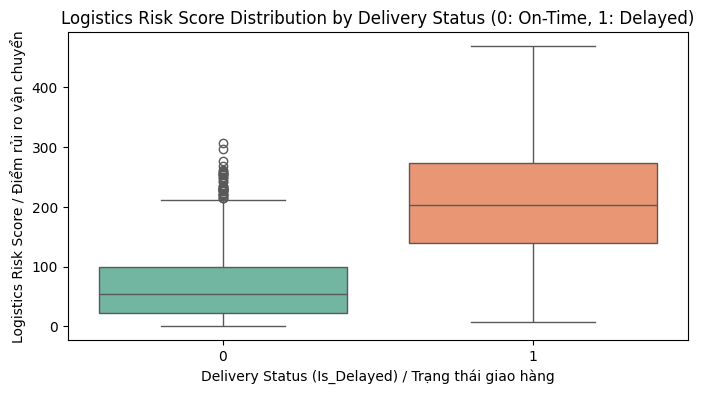

In [23]:
#FEATURE ENGINEERING & VISUALIZATION
import matplotlib.pyplot as plt #Import plotting library / Nhập thư viện vẽ biểu đồ cơ bản
import seaborn as sns            #Import statistical visualization library / Nhập thư viện vẽ biểu đồ thống kê

#Feature 1: Price Variance Ratio (%) / Tạo cột 1: Tỷ lệ % chênh lệch giá so với thị trường
df_clean['Price_Variance_Ratio'] = (df_clean['Quoted_Unit_Price'] - df_clean['Market_Benchmark_Price']) / df_clean['Market_Benchmark_Price']

#Feature 2: Logistics Risk Score / Tạo cột 2: Điểm rủi ro vận chuyển (Khoảng cách x Tỷ lệ từng trễ trong quá khứ)
df_clean['Logistics_Risk_Score'] = df_clean['Distance_km'] * (1 - df_clean['Historical_OnTime_Rate'])

#Plot boxplot to compare risk scores / Vẽ biểu đồ hộp so sánh điểm rủi ro giữa đơn đúng hạn (0) và đơn trễ (1)
plt.figure(figsize=(8, 4)) #Set chart size / Thiết lập kích thước khung hình
sns.boxplot(x='Is_Delayed', y='Logistics_Risk_Score', data=df_clean, palette='Set2') #Draw boxplot / Vẽ biểu đồ hộp
plt.title('Logistics Risk Score Distribution by Delivery Status (0: On-Time, 1: Delayed)') #Chart title / Tiêu đề biểu đồ
plt.xlabel('Delivery Status (Is_Delayed) / Trạng thái giao hàng') #X-axis label / Nhãn trục ngang
plt.ylabel('Logistics Risk Score / Điểm rủi ro vận chuyển') #Y-axis label / Nhãn trục dọc
plt.show() #Display chart / Hiển thị biểu đồ

In [24]:
#BASELINE MODELING & EVALUATION (HUẤN LUYỆN & ĐÁNH GIÁ MÔ HÌNH)
#Import Machine Learning tools from scikit-learn / Nhập các công cụ Học máy từ thư viện scikit-learn
from sklearn.model_selection import train_test_split, cross_val_score # Data splitting & cross-validation / Chia dữ liệu & kiểm tra chéo
from sklearn.preprocessing import StandardScaler                      # Feature scaling / Chuẩn hóa thang đo dữ liệu
from sklearn.linear_model import LogisticRegression                   # Baseline model 1 / Mô hình cơ bản 1 (Logistic Regression)
from sklearn.ensemble import RandomForestClassifier                   # Baseline model 2 / Mô hình cơ bản 2 (Random Forest)
from sklearn.metrics import classification_report                     # Evaluation metrics report / Bảng báo cáo điểm đánh giá

#Ensure engineered features exist / Tự động tạo lại 2 cột đặc trưng nếu chưa chạy Ô 4
if 'Price_Variance_Ratio' not in df_clean.columns:
    df_clean['Price_Variance_Ratio'] = (df_clean['Quoted_Unit_Price'] - df_clean['Market_Benchmark_Price']) / df_clean['Market_Benchmark_Price']
if 'Logistics_Risk_Score' not in df_clean.columns:
    df_clean['Logistics_Risk_Score'] = df_clean['Distance_km'] * (1 - df_clean['Historical_OnTime_Rate'])

#Select input features (X) and target label (y) / Chọn các cột đặc trưng đầu vào (X) và nhãn cần dự đoán (y)
features = ['Order_Quantity', 'Distance_km', 'Historical_OnTime_Rate', 'Price_Variance_Ratio', 'Logistics_Risk_Score', 'Category', 'Payment_Terms']
X = pd.get_dummies(df_clean[features], drop_first=True) # One-hot encode text columns to 0/1 / Đổi cột chữ thành số 0 và 1
y = df_clean['Is_Delayed'] # Target variable / Cột đáp án (0 hoặc 1)

#Split dataset into 80% Train and 20% Test / Chia dữ liệu: 80% để dạy máy học, 20% để kiểm tra máy
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#Standardize numerical scales for Logistic Regression / Đưa các con số về cùng thang đo chuẩn
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train) #Fit and transform training data / Tính thang đo và áp dụng cho tập học
X_test_scaled = scaler.transform(X_test)       #Apply same scale to test data / Áp dụng thang đo đó cho tập kiểm tra

#MODEL 1: LOGISTIC REGRESSION (BASELINE) / MÔ HÌNH 1
lr_model = LogisticRegression(random_state=42) #Initialize model / Khởi tạo mô hình Logistic Regression
lr_model.fit(X_train_scaled, y_train)          #Train model on training data / Cho mô hình học từ dữ liệu Train
y_pred_lr = lr_model.predict(X_test_scaled)    #Predict on test data / Dự đoán kết quả trên tập Test

#MODEL 2: RANDOM FOREST CLASSIFIER / MÔ HÌNH 2
rf_model = RandomForestClassifier(n_estimators=100, random_state=42) #Initialize Random Forest (100 trees) / Khởi tạo mô hình Random Forest
rf_model.fit(X_train, y_train)                 #Train model / Cho mô hình học
y_pred_rf = rf_model.predict(X_test)           #Predict on test data / Dự đoán trên tập Test

#Run 5-Fold Cross-Validation to verify stability / Kiểm tra chéo 5 lần để đảm bảo kết quả ổn định
cv_scores = cross_val_score(rf_model, X_train, y_train, cv=5, scoring='f1')

#Print evaluation metrics (Precision, Recall, F1-Score) / In bảng điểm đánh giá độ chính xác
print("=== MODEL 1: LOGISTIC REGRESSION RESULTS / KẾT QUẢ LOGISTIC REGRESSION ===")
print(classification_report(y_test, y_pred_lr))

print("=== MODEL 2: RANDOM FOREST RESULTS / KẾT QUẢ RANDOM FOREST ===")
print(classification_report(y_test, y_pred_rf))
print(f"5-Fold Cross-Validation F1-Score (Random Forest): {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")

=== MODEL 1: LOGISTIC REGRESSION RESULTS / KẾT QUẢ LOGISTIC REGRESSION ===
              precision    recall  f1-score   support

           0       0.90      0.90      0.90       347
           1       0.86      0.86      0.86       241

    accuracy                           0.88       588
   macro avg       0.88      0.88      0.88       588
weighted avg       0.88      0.88      0.88       588

=== MODEL 2: RANDOM FOREST RESULTS / KẾT QUẢ RANDOM FOREST ===
              precision    recall  f1-score   support

           0       0.88      0.89      0.89       347
           1       0.84      0.83      0.83       241

    accuracy                           0.86       588
   macro avg       0.86      0.86      0.86       588
weighted avg       0.86      0.86      0.86       588

5-Fold Cross-Validation F1-Score (Random Forest): 0.828 (+/- 0.018)
